# Decision Tree | TON_IoT | target: `label` (binary)
Tayyab (SP24-BCS-004). Settings and decisions are tracked in `AUDIT_LOG.md`; hyperparameter sources are in `HYPERPARAMETER_SOURCES.md` (both in the project root).

**Plan:** 20% test set (stratified), then stratified 5-fold on the other 80% (64% train / 16% validation per fold). Hyperparameters come from the papers, and the folds measure validation performance and stability, not tuning. The test set was used more than once: `max_depth=5` was replaced by `None` after the first test results, so the test scores may be slightly optimistic.

## 1. Imports and setup
**Q1.** Import the libraries and set a global `RANDOM_STATE` (same value for every model).

In [1]:
import time
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             log_loss, matthews_corrcoef, confusion_matrix, classification_report)

RANDOM_STATE = 42

**Q2.** Define the Decision Tree hyperparameters (fixed, from the papers) and the duplicate-removal switch.

*Why a switch?* Whether to remove duplicates is still undecided in the team. See Q8.

**What to do:** create a dictionary `HP` with: `criterion='gini'`, `splitter='best'`, `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, `random_state=RANDOM_STATE`. Create a variable `DEDUPLICATE = False`.

In [2]:
# Dataset-specific hyperparameters (see HYPERPARAMETER_SOURCES.md)
# Source: Dharini, Janani & Katiravan (2026), "Efficient detection of intrusions in TON-IoT dataset using hybrid
# feature selection approach", Scientific Reports 16:7763, doi:10.1038/s41598-026-37834-y
# ("gini criterion, no fixed maximum depth, minimum split of two samples, and one sample per leaf"; random_state = 42)
HP = dict(criterion="gini", splitter="best", max_depth=None, min_samples_split=2, min_samples_leaf=1, random_state=RANDOM_STATE)

# Previous values (Li et al. 2024 / Sharma et al. 2025): max_depth=5, min_samples_split=5 -> underfitted `type`

DEDUPLICATE = False

## 2. Load the dataset
**Q3.** Load `train_test_network.csv`. How many rows and columns are there? (Expected: 211,043 x 44.)

In [3]:
df =pd.read_csv("../TON_IoT/../../../train_test_network.csv")

## 3. Explore the data
**Q4.** Show `head()`, `info()`, `describe()` and the class distribution of `label`. Is it balanced? Which class is the rarest?

In [4]:
df.shape

(211043, 44)

In [5]:
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  str    
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  str    
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  str    
 5   service                 211043 non-null  str    
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  str    
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes            211043 

In [7]:
df.describe()

,src_port,dst_port,duration,src_bytes,dst_bytes,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,dst_ip_bytes,dns_qclass,dns_qtype,dns_rcode,http_request_body_len,http_response_body_len,http_status_code,label
count,211043.000000,211043.000000,211043.000000,2.110430e+05,2.110430e+05,2.110430e+05,211043.000000,2.110430e+05,211043.000000,2.110430e+05,211043.000000,211043.000000,211043.000000,211043.000000,2.110430e+05,211043.000000,211043.000000
mean,38646.519543,3495.153770,7.700887,2.581136e+05,2.588046e+05,3.443234e+04,9.595220,7.760822e+02,3.846861,1.584687e+03,227.630805,3.610909,0.123989,0.065418,1.449295e+02,0.303905,0.763081
std,19307.271048,10191.624778,564.141946,1.709490e+07,1.802563e+07,5.261621e+06,91.778821,2.229703e+04,330.705796,1.901795e+05,2720.713562,23.797747,0.598804,9.243405,3.047244e+04,8.270377,0.425193
min,1.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,34608.000000,65.000000,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,4.800000e+01,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
50%,44754.000000,80.000000,0.000170,0.000000e+00,0.000000e+00,0.000000e+00,1.000000,8.200000e+01,1.000000,4.000000e+01,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
75%,51133.000000,1253.000000,0.054196,1.300000e+02,8.900000e+01,0.000000e+00,4.000000,4.150000e+02,2.000000,1.340000e+02,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,1.000000
max,65528.000000,65467.000000,93516.929170,3.890855e+09,3.913853e+09,1.854527e+09,24623.000000,6.522626e+06,121942.000000,8.639552e+07,32769.000000,255.000000,5.000000,2338.000000,1.342438e+07,404.000000,1.000000


<Axes: title={'center': 'Classs Distribution: label'}, xlabel='label'>

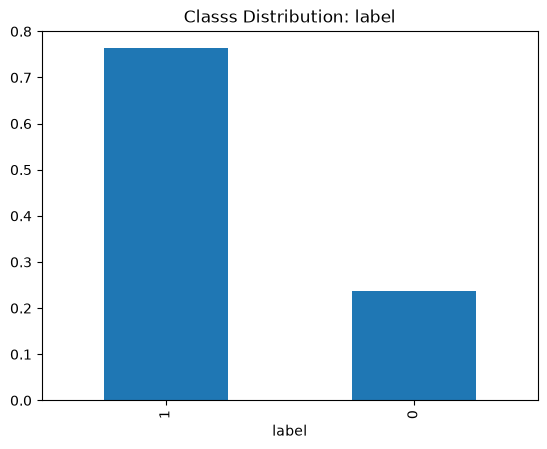

In [8]:
df["label"].value_counts()
df["label"].value_counts(normalize =True).plot(kind="bar", title = "Classs Distribution: label")

In [9]:
df["label"].value_counts(normalize=True).round(4)

label
1    0.7631
0    0.2369
Name: proportion, dtype: float64

**Q5.** Replace the `-` placeholders with NaN and list the percentage of missing values per column.

In [10]:
df = df.replace("-", np.nan)
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,NaN,290.371539,101568,2592,OTH,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000102,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000148,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000113,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,NaN,0.000130,0,0,REJ,...,0,0,NaN,NaN,NaN,NaN,NaN,NaN,1,backdoor


In [11]:
# Missing values per column
missing_counts = df.isnull().sum()
print(missing_counts)

src_ip                         0
src_port                       0
dst_ip                         0
dst_port                       0
proto                          0
service                   132032
duration                       0
src_bytes                      0
dst_bytes                      0
conn_state                     0
missed_bytes                   0
src_pkts                       0
src_ip_bytes                   0
dst_pkts                       0
dst_ip_bytes                   0
dns_query                 176198
dns_qclass                     0
dns_qtype                      0
dns_rcode                      0
dns_AA                    176030
dns_RD                    176030
dns_RA                    176030
dns_rejected              176030
ssl_version               210642
ssl_cipher                210642
ssl_resumed               210642
ssl_established           210642
ssl_subject               211032
ssl_issuer                211032
http_trans_depth          210740
http_metho

In [12]:

missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

src_ip                     0.000000
src_port                   0.000000
dst_ip                     0.000000
dst_port                   0.000000
proto                      0.000000
service                   62.561658
duration                   0.000000
src_bytes                  0.000000
dst_bytes                  0.000000
conn_state                 0.000000
missed_bytes               0.000000
src_pkts                   0.000000
src_ip_bytes               0.000000
dst_pkts                   0.000000
dst_ip_bytes               0.000000
dns_query                 83.489147
dns_qclass                 0.000000
dns_qtype                  0.000000
dns_rcode                  0.000000
dns_AA                    83.409542
dns_RD                    83.409542
dns_RA                    83.409542
dns_rejected              83.409542
ssl_version               99.809991
ssl_cipher                99.809991
ssl_resumed               99.809991
ssl_established           99.809991
ssl_subject               99

In [13]:
for i in missing_percentage.index:
    if missing_percentage[i] > 95:
        print(f"Column '{i}' has more than 95% missing values and will be dropped.")

Column 'ssl_version' has more than 95% missing values and will be dropped.
Column 'ssl_cipher' has more than 95% missing values and will be dropped.
Column 'ssl_resumed' has more than 95% missing values and will be dropped.
Column 'ssl_established' has more than 95% missing values and will be dropped.
Column 'ssl_subject' has more than 95% missing values and will be dropped.
Column 'ssl_issuer' has more than 95% missing values and will be dropped.
Column 'http_trans_depth' has more than 95% missing values and will be dropped.
Column 'http_method' has more than 95% missing values and will be dropped.
Column 'http_uri' has more than 95% missing values and will be dropped.
Column 'http_version' has more than 95% missing values and will be dropped.
Column 'http_user_agent' has more than 95% missing values and will be dropped.
Column 'http_orig_mime_types' has more than 95% missing values and will be dropped.
Column 'http_resp_mime_types' has more than 95% missing values and will be dropped

In [14]:
missing_columns = missing_percentage[missing_percentage >95].index.tolist()
print(missing_columns)

['ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']


In [15]:
count = len(missing_columns)
print(count)

16


## 4. Clean the data
**Q6.** Drop columns that are more than 95% empty. How many were dropped? (Expected: 16, the `http_*`, `ssl_*`, `weird_*` columns.)

In [16]:
df.shape

(211043, 44)

In [17]:
df = df.drop(columns=missing_columns)

In [18]:
df.shape

(211043, 28)

**Q7.** Drop the identifier columns (`src_ip`, `dst_ip`, `src_port`, `dst_port`). Why do they cause overfitting?

In [19]:
# We dropped them beacuse a tree that memorized them would not work on a different network
df = df.drop(columns=["src_ip","dst_ip","src_port","dst_port"])

In [20]:
df.shape

(211043, 24)

**Q8.** How many duplicate rows are there now? Duplicates can land in both train and test, which inflates the scores; but removing them changes the dataset a lot (expected: ~117k duplicates, and `ransomware` falls from 20,000 to ~260 rows). Run once with `DEDUPLICATE = False` and once with `True`, and write both results in `AUDIT_LOG.md`.

**What to do:** print the duplicate count, then remove duplicates only `if DEDUPLICATE:`. Print the row count before and after.

In [21]:
no_of_duplicates = df.duplicated().sum()
print(no_of_duplicates)

117159


In [22]:
if DEDUPLICATE:
    df = df.drop_duplicates().reset_index(drop=True)
    print("Rows after duplicates removed:", df.duplicated().sum())

## 5. Targets and split
**Q9.** Build the features `X` and the target `y` (`label`), without the other target column (leakage). Split 80/20 with stratification. Do the class shares match between train and test?

In [23]:
X = df.drop(columns=["label","type"])
y = df["label"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2, random_state=RANDOM_STATE, stratify=df["type"])

In [24]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(168834, 22)

 (42209, 22) (168834,) (42209,)


## 6. Encode the features
**Q10.** Encode the categorical columns using the training set only: missing values as their own category, one-hot for low-cardinality columns, frequency encoding for `dns_query`. Why are encoders fitted after the split? Why is no scaling needed for trees?

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   proto                   211043 non-null  str    
 1   service                 79011 non-null   str    
 2   duration                211043 non-null  float64
 3   src_bytes               211043 non-null  int64  
 4   dst_bytes               211043 non-null  int64  
 5   conn_state              211043 non-null  str    
 6   missed_bytes            211043 non-null  int64  
 7   src_pkts                211043 non-null  int64  
 8   src_ip_bytes            211043 non-null  int64  
 9   dst_pkts                211043 non-null  int64  
 10  dst_ip_bytes            211043 non-null  int64  
 11  dns_query               34845 non-null   str    
 12  dns_qclass              211043 non-null  int64  
 13  dns_qtype               211043 non-null  int64  
 14  dns_rcode               211043 

In [26]:
df.head()

,proto,service,duration,src_bytes,dst_bytes,conn_state,missed_bytes,src_pkts,src_ip_bytes,dst_pkts,...,dns_rcode,dns_AA,dns_RD,dns_RA,dns_rejected,http_request_body_len,http_response_body_len,http_status_code,label,type
0,tcp,NaN,290.371539,101568,2592,OTH,0,108,108064,31,...,0,NaN,NaN,NaN,NaN,0,0,0,1,backdoor
1,tcp,NaN,0.000102,0,0,REJ,0,1,52,1,...,0,NaN,NaN,NaN,NaN,0,0,0,1,backdoor
2,tcp,NaN,0.000148,0,0,REJ,0,1,52,1,...,0,NaN,NaN,NaN,NaN,0,0,0,1,backdoor
3,tcp,NaN,0.000113,0,0,REJ,0,1,48,1,...,0,NaN,NaN,NaN,NaN,0,0,0,1,backdoor
4,tcp,NaN,0.000130,0,0,REJ,0,1,52,1,...,0,NaN,NaN,NaN,NaN,0,0,0,1,backdoor


In [27]:
# Encoders learn ONLY from the training set, then are applied to the test set.
onehot_cols = ["proto", "service", "conn_state", "dns_AA", "dns_RD", "dns_RA", "dns_rejected"]
freq_col = "dns_query"   # 700+ different values: one-hot would add too many columns

X_train = X_train.copy()
X_test = X_test.copy()

# Missing values in categorical columns become their own category
for c in onehot_cols + [freq_col]:
    X_train[c] = X_train[c].fillna("missing")
    X_test[c] = X_test[c].fillna("missing")

# Frequency encoding for dns_query (frequencies from the training set only)
freq_map = X_train[freq_col].value_counts(normalize=True)
X_train[freq_col] = X_train[freq_col].map(freq_map)
X_test[freq_col] = X_test[freq_col].map(freq_map).fillna(0)   # unseen in training -> 0

# One-hot encoding; the test set is aligned to the training columns
X_train = pd.get_dummies(X_train, columns=onehot_cols).astype(float)
X_test = pd.get_dummies(X_test, columns=onehot_cols).reindex(columns=X_train.columns, fill_value=0).astype(float)

print("Features after encoding:", X_train.shape[1])
print("Any NaN left?", X_train.isna().any().any(), X_test.isna().any().any())
# No scaling: decision trees split on thresholds, so feature scale does not matter.

Features after encoding: 52
Any NaN left? False False


## 7. Validation with stratified 5-fold
**Q11.** With the fixed hyperparameters, train on each fold's training part and score on its validation part. Is the validation score stable across folds (small standard deviation)? Does each fold keep every class?

In [28]:
# Stratified 5-fold on the 80% training set: each fold = 64% train / 16% validation of the full data
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fold_rows = []
for i, (tr, va) in enumerate(skf.split(X_train, y_train), start=1):
    m = DecisionTreeClassifier(**HP)
    m.fit(X_train.iloc[tr], y_train.iloc[tr])
    pred = m.predict(X_train.iloc[va])
    fold_rows.append({"fold": i, "n_train": len(tr), "n_val": len(va),
                       "val_accuracy": accuracy_score(y_train.iloc[va], pred),
                       "val_F1": f1_score(y_train.iloc[va], pred)})
fold_df = pd.DataFrame(fold_rows)
display(fold_df.round(4))
print("Mean validation accuracy: %.4f +/- %.4f" % (fold_df.val_accuracy.mean(), fold_df.val_accuracy.std()))
print("Mean validation F1: %.4f +/- %.4f" % (fold_df["val_F1"].mean(), fold_df["val_F1"].std()))

,fold,n_train,n_val,val_accuracy,val_F1
0,1,135067,33767,0.9979,0.9986
1,2,135067,33767,0.9972,0.9982
2,3,135067,33767,0.9979,0.9986
3,4,135067,33767,0.9977,0.9985
4,5,135068,33766,0.9980,0.9987


Mean validation accuracy: 0.9977 +/- 0.0003
Mean validation F1: 0.9985 +/- 0.0002


## 8. Final model
**Q12.** Train the final model on the full 80% training set with the same hyperparameters. How long does it take? How deep is the tree, and how many leaves?

In [29]:
model = DecisionTreeClassifier(**HP)
t0 = time.perf_counter()
model.fit(X_train, y_train)
train_time = time.perf_counter() - t0
print("Training time: %.3f s" % train_time)
print("Depth:", model.get_depth(), " Leaves:", model.get_n_leaves())

Training time: 1.137 s
Depth: 31  Leaves: 431


## 9. Evaluation on the test set (used more than once: `max_depth` was revised after the first test results)
**Q13.** Predict on the test set and measure the inference latency (ms per sample, `predict()` only).

In [30]:
# Inference latency = time of predict() on the whole test set / number of test rows (ms per sample)
t0 = time.perf_counter()
y_pred = model.predict(X_test)
latency_ms = (time.perf_counter() - t0) / len(X_test) * 1000
y_proba = model.predict_proba(X_test)
print("Latency: %.6f ms/sample" % latency_ms)

Latency: 0.000412 ms/sample


**Q14.** Compute every metric required by `Results.xlsx`: Accuracy, Precision, Recall, F1, ROC-AUC, Log-Loss, FPR, MCC, and TP/TN/FP/FN.

In [31]:
accuracy  = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall    = recall_score(y_test, y_pred)
f1        = f1_score(y_test, y_pred)
roc_auc   = roc_auc_score(y_test, y_proba[:, 1])
logloss   = log_loss(y_test, y_proba)
mcc       = matthews_corrcoef(y_test, y_pred)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
fpr = fp / (fp + tn)

print(f"Accuracy {accuracy:.4f} | Precision {precision:.4f} | Recall {recall:.4f} | F1 {f1:.4f}")
print(f"ROC-AUC {roc_auc:.4f} | Log-Loss {logloss:.4f} | FPR {fpr:.4f} | MCC {mcc:.4f}")
print(f"TP {tp} | TN {tn} | FP {fp} | FN {fn}")

Accuracy 0.9981 | Precision 0.9986 | Recall 0.9989 | F1 0.9988
ROC-AUC 0.9972 | Log-Loss 0.0668 | FPR 0.0044 | MCC 0.9948
TP 32173 | TN 9956 | FP 44 | FN 36


**Q15.** Compare train and test accuracy. Is the tree overfitting or underfitting? What do the validation-fold scores say?

In [32]:
train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, y_pred)
print(f"Train accuracy {train_acc:.4f} | Test accuracy {test_acc:.4f} | Gap {train_acc - test_acc:+.4f}")

Train accuracy 0.9998 | Test accuracy 0.9981 | Gap +0.0017


## 10. Visualizations
**Q16.** Plot the confusion matrix and the ROC curve.

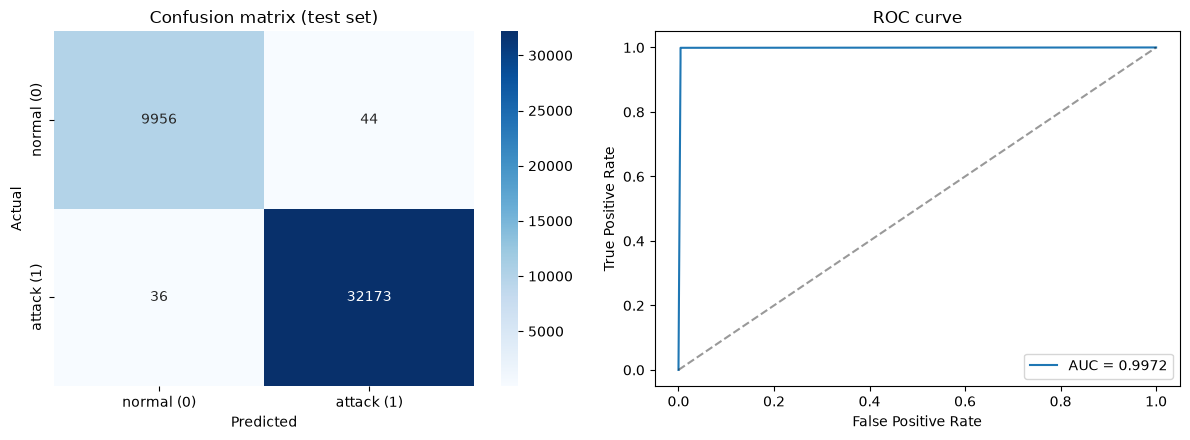

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["normal (0)", "attack (1)"], yticklabels=["normal (0)", "attack (1)"])
ax[0].set(title="Confusion matrix (test set)", xlabel="Predicted", ylabel="Actual")

fpr_c, tpr_c, _ = roc_curve(y_test, y_proba[:, 1])
ax[1].plot(fpr_c, tpr_c, label=f"AUC = {roc_auc:.4f}")
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[1].set(title="ROC curve", xlabel="False Positive Rate", ylabel="True Positive Rate")
ax[1].legend()
plt.tight_layout()
plt.show()

**Q17.** Which features matter most to the tree?

proto_tcp           0.3690
src_pkts            0.3107
dns_rejected_T      0.1047
dst_pkts            0.0780
dns_RA_T            0.0705
duration            0.0183
src_ip_bytes        0.0137
src_bytes           0.0066
dst_ip_bytes        0.0054
http_status_code    0.0043
dtype: float64

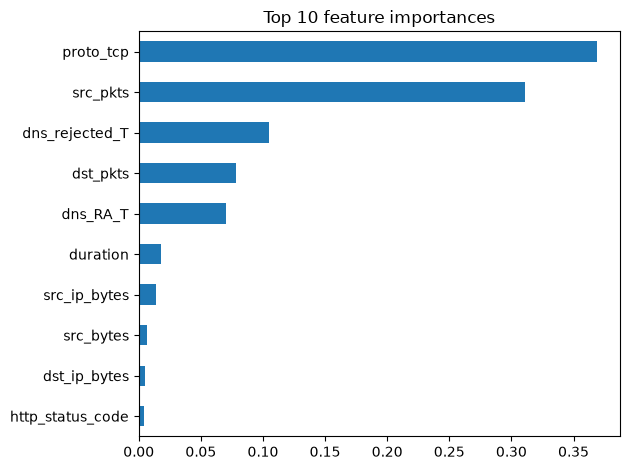

In [34]:
importances = pd.Series(model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
display(importances.head(10).round(4))
importances.head(10).sort_values().plot(kind="barh", title="Top 10 feature importances")
plt.tight_layout()
plt.show()

**Q18.** Plot the top levels of the tree. Do the first splits make sense for network attacks?

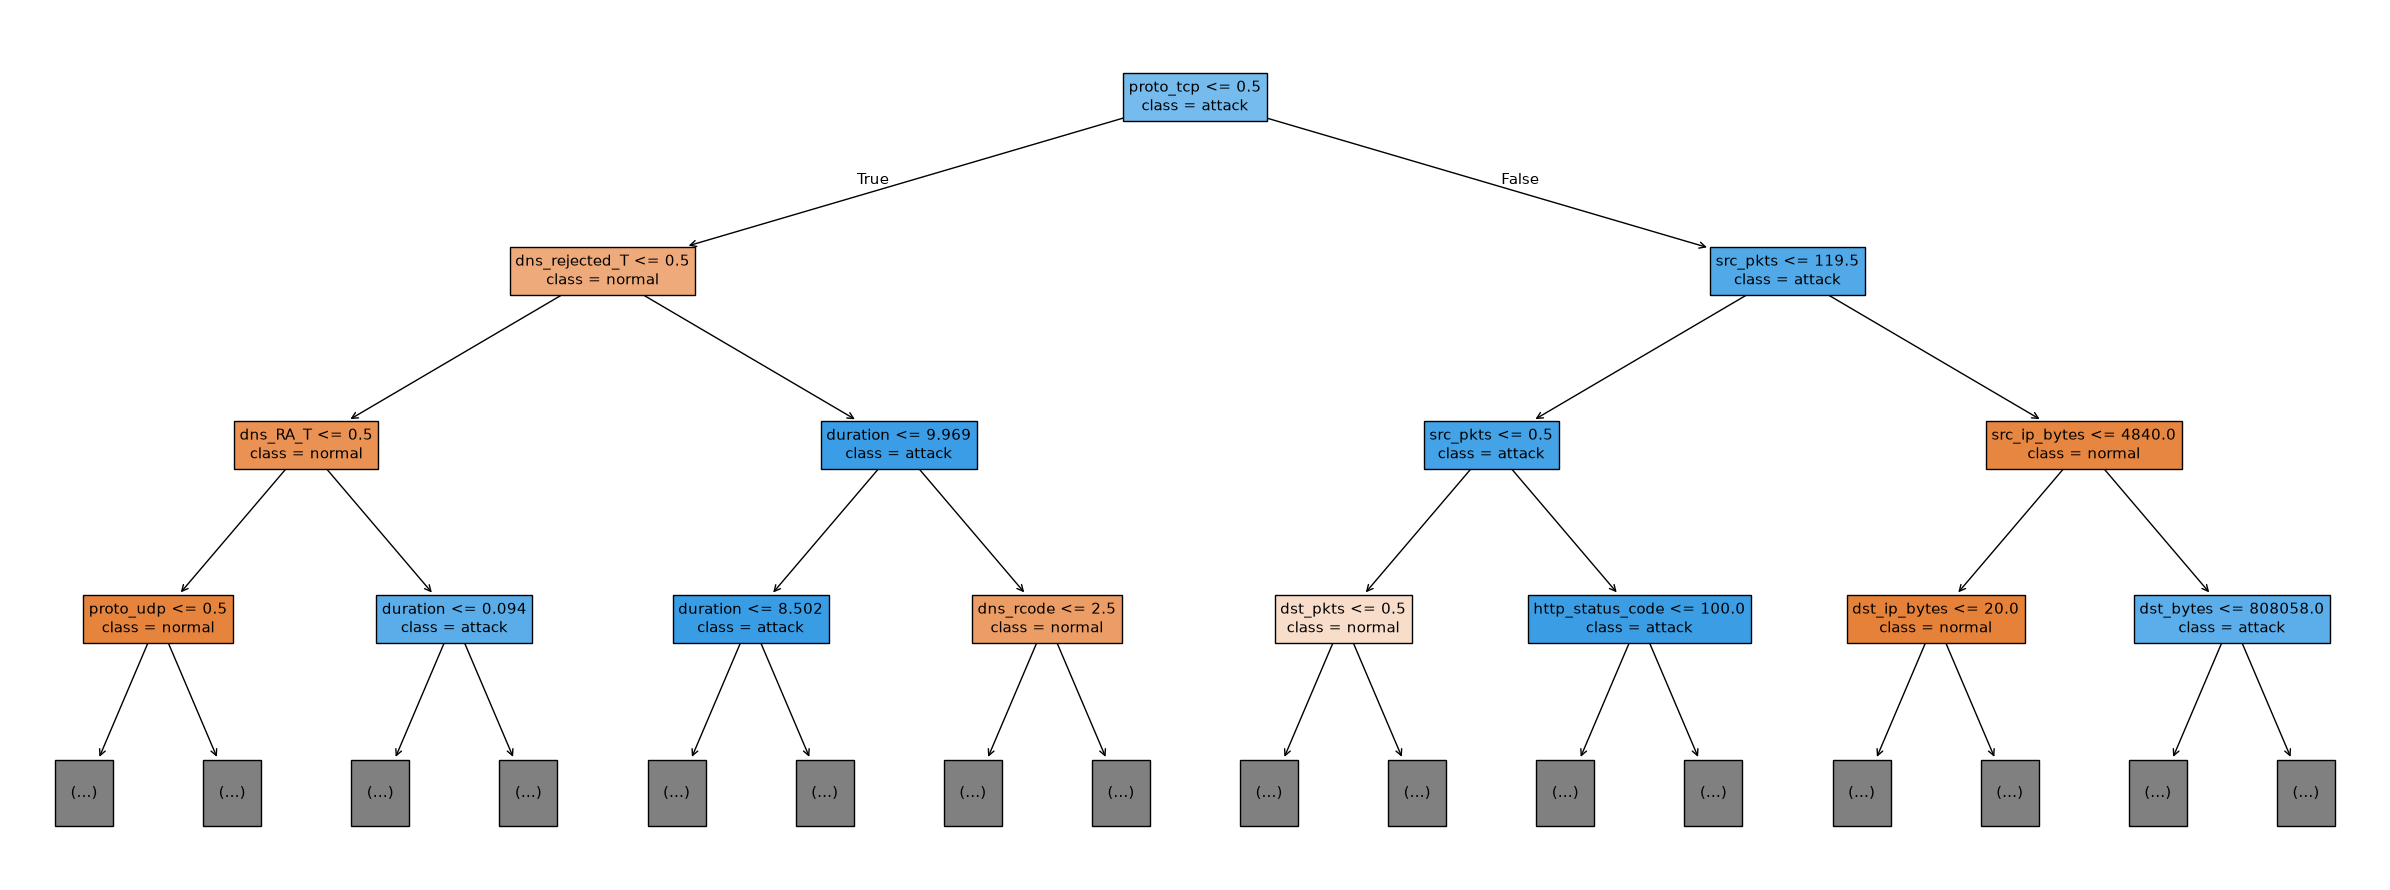

In [35]:
# Only the first 3 levels of the tree
fig, ax = plt.subplots(figsize=(24, 9))
nodes = plot_tree(model, feature_names=list(X_train.columns), class_names=["normal", "attack"], filled=True,
                  max_depth=3, impurity=False, fontsize=11, ax=ax)

# Keep only the split question and the predicted class in each box;
# the "samples" and "value = [...]" lines make the boxes too wide and they overlap
for node in nodes:
    text = node.get_text()
    if "value" in text:
        keep = [line for line in text.splitlines() if "<=" in line or line.startswith("class")]
        node.set_text("\n".join(keep))

plt.tight_layout()
plt.show()

## 11. Results table
**Q19.** Collect all numbers in one table, in the same order as the *Decision Trees* row of `Results.xlsx`. Check that TP+TN+FP+FN equals the number of test rows (for `type`, it is per class). Copy the numbers into `AUDIT_LOG.md`. (Writing into `Results.xlsx` is decided later.)

In [36]:
results = pd.DataFrame([{
    "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1-Score": f1,
    "ROC-AUC": roc_auc, "Log-Loss": logloss, "FPR": fpr, "MCC": mcc,
    "Inference Latency (ms/sample)": latency_ms, "Training time (s)": train_time,
    **{'TP': tp, 'TN': tn, 'FP': fp, 'FN': fn},
    "Test rows": len(y_test),
}], index=["Decision Tree - label"])
display(results.T)

,Decision Tree - label
Accuracy,0.998105
Precision,0.998634
Recall,0.998882
F1-Score,0.998758
ROC-AUC,0.997228
Log-Loss,0.066796
FPR,0.004400
MCC,0.994757
Inference Latency (ms/sample),0.000412
Training time (s),1.137182


## 12. Discussion (for the report)
**Q20.** Compare with the KNN, Random Forest and XGBoost rows (accuracy, F1, MCC, latency).

**Q21.** Which kind of error matters more here, false positives or false negatives, and what does the model's FPR say?

**Q22.** Limitations (unlimited depth chosen after the first test results, duplicates, dataset-specific features).

**Your notes:**